In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Загружаем наши очищенные данные
profile = pd.read_parquet('../data/processed/profile_clean.parquet')
transcript = pd.read_parquet('../data/processed/transcript_clean.parquet')
portfolio = pd.read_parquet('../data/processed/portfolio.parquet')

In [2]:
# Оставляем только полученные офферы
offers_received = transcript[transcript['event'] == 'offer received'].copy()

# Добавляем информацию о длительности оффера (duration) из портфолио
offers_received = offers_received.merge(portfolio[['id', 'duration']], left_on='offer_id', right_on='id', how='left')

# Переведем duration в минуты (если time в данных в минутах, а duration в днях)
# В датасете Udacity duration указан в днях (например, 7 дней). 
# Время (time) в транскрипте тоже в днях (0, 1, 2... 30). Проверим это.
print(offers_received[['person', 'time', 'duration']].head())

                             person  time  duration
0  78afa995795e4d85b5d9ceeca43f5fef     0         7
1  a03223e636434f42ac4c3df47e8bac43     0        10
2  e2127556f4f64592b11af22de27a7932     0         7
3  8ec6ce2a7e7949b1bf142def7d0e0586     0        10
4  68617ca6246f4fbc85e91a2a49552598     0         5


In [3]:
transactions = transcript[transcript['event'] == 'transaction'].copy()
# Нам нужны только время и пользователь. Сумма amount нам сейчас не важна, важна частота
transactions = transactions[['person', 'time', 'amount']]

In [4]:
# Соединяем офферы и транзакции по пользователю
# Получится таблица, где у каждого оффера будет список ВСЕХ транзакций пользователя
merged = offers_received.merge(transactions, on='person', suffixes=('_offer', '_trans'))

# Теперь фильтруем: оставляем только те транзакции, которые произошли ПОСЛЕ получения оффера
# И до окончания срока действия оффера (time_offer + duration)
converted = merged[
    (merged['time_trans'] >= merged['time_offer']) & 
    (merged['time_trans'] <= merged['time_offer'] + merged['duration'])
]

# Теперь нам нужно понять: сколько офферов привели к конверсии, а сколько нет.
# Для этого создадим колонку is_converted = 1 для тех, кто попал в фильтр выше.
converted['is_converted'] = 1

In [5]:
# Берем список всех полученных офферов
final_df = offers_received[['person', 'offer_id', 'time', 'duration']].copy()

# Мержим с конверсиями (left join, чтобы сохранить всех, у кого не было конверсии)
# Но нам нужно избежать дублирования, если было несколько транзакций (берем уникальные)
conversion_status = converted[['person', 'offer_id', 'is_converted']].drop_duplicates(subset=['person', 'offer_id'])

final_df = final_df.merge(conversion_status, on=['person', 'offer_id'], how='left')

# Заполняем пропуски нулями (если не было конверсии)
final_df['is_converted'] = final_df['is_converted'].fillna(0).astype(int)

print("Размер итоговой таблицы:", final_df.shape)
print("Средняя конверсия:", final_df['is_converted'].mean().round(4))

Размер итоговой таблицы: (76277, 5)
Средняя конверсия: 0.1442


In [6]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# ==========================================
# 1. ПОДГОТОВКА ДАННЫХ (Все мерджи за один раз)
# ==========================================

# Подтягиваем offer_type из портфолио
# В final_df колонка offer_id, в portfolio - id. После мерджа удаляем id, чтобы не мешал.
df_model = final_df.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id', how='left').drop(columns=['id'])

# Подтягиваем демографию (возраст, пол, доход) из профиля
# В df_model колонка person, в profile - id. После мерджа удаляем id.
df_model = df_model.merge(profile[['id', 'age', 'gender', 'income']], left_on='person', right_on='id', how='left').drop(columns=['id'])

# Создаем возрастные группы
df_model['age_group'] = pd.cut(df_model['age'], bins=[0, 25, 35, 50, 100], labels=['<25', '25-35', '35-50', '50+'])

# ==========================================
# 2. ПРОВЕРКА БАЛАНСА ГРУПП (SRM Check)
# ==========================================
print("--- Размеры групп по типам офферов ---")
print(df_model['offer_type'].value_counts())

print("\n--- Средний возраст и доход по типам офферов ---")
print(df_model.groupby('offer_type')[['age', 'income']].mean().round(1))

print("\n--- Доли пола по типам офферов (в %) ---")
print(pd.crosstab(df_model['offer_type'], df_model['gender'], normalize='index').round(3) * 100)

# ==========================================
# 3. СВОДНАЯ ТАБЛИЦА (Age x Offer Type)
# ==========================================
print("\n--- Конверсия по возрастным группам и типам офферов ---")
pivot_table = df_model.pivot_table(index='age_group', columns='offer_type', values='is_converted', aggfunc='mean')
display(pivot_table.round(3))

# ==========================================
# 4. ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ (Cluster-Robust SE)
# ==========================================
# Создаем бинарные признаки
df_model['is_discount'] = (df_model['offer_type'] == 'discount').astype(int)
df_model['is_young'] = (df_model['age_group'] == '25-35').astype(int)

# Обучаем модель с кластеризованными ошибками по 'person'
model = smf.logit(
    'is_converted ~ is_discount + is_young + is_discount:is_young', 
    data=df_model
).fit(
    cov_type='cluster', 
    cov_kwds={'groups': df_model['person']}
)

print("\n--- Логистическая регрессия (Cluster-Robust) ---")
print(model.summary())

# Считаем Odds Ratios (для бизнеса)
print("\n--- Odds Ratios (во сколько раз меняются шансы) ---")
print(np.exp(model.params).round(3))

--- Размеры групп по типам офферов ---
offer_type
discount         30543
bogo             30499
informational    15235
Name: count, dtype: int64

--- Средний возраст и доход по типам офферов ---
                age   income
offer_type                  
bogo           54.3  65424.6
discount       54.3  65318.9
informational  54.6  65371.7

--- Доли пола по типам офферов (в %) ---
gender            F     M    O
offer_type                    
bogo           41.4  57.3  1.3
discount       41.0  57.6  1.4
informational  41.6  56.9  1.5

--- Конверсия по возрастным группам и типам офферов ---


offer_type,bogo,discount,informational
age_group,,,
<25,0.163,0.205,0.097
25-35,0.175,0.212,0.114
35-50,0.155,0.176,0.100
50+,0.127,0.170,0.084


Optimization terminated successfully.
         Current function value: 0.409429
         Iterations 6

--- Логистическая регрессия (Cluster-Robust) ---
                           Logit Regression Results                           
Dep. Variable:           is_converted   No. Observations:                76277
Model:                          Logit   Df Residuals:                    76273
Method:                           MLE   Df Model:                            3
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                0.007530
Time:                        13:21:47   Log-Likelihood:                -31230.
converged:                       True   LL-Null:                       -31467.
Covariance Type:              cluster   LLR p-value:                2.183e-102
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               -1.9919      0

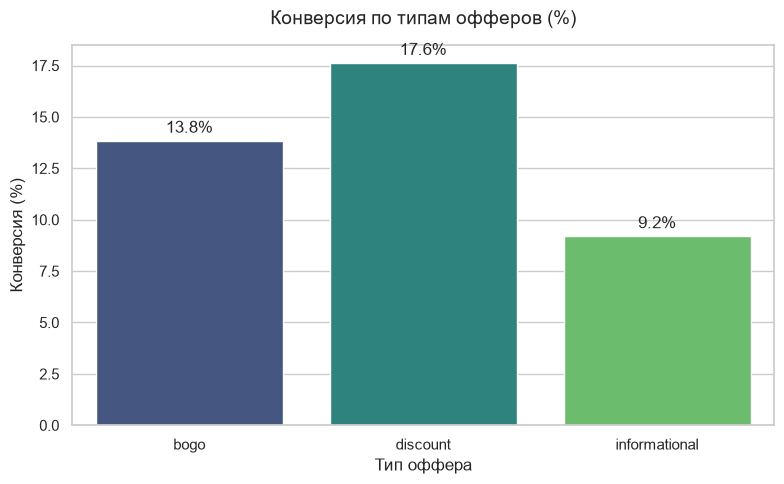

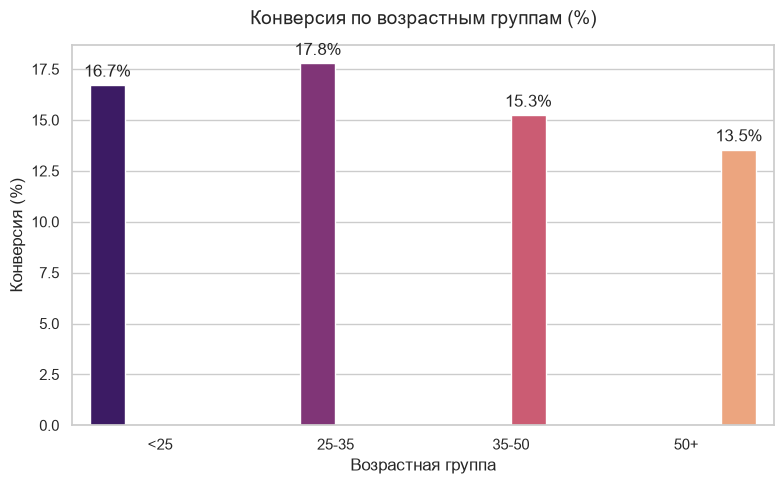

Графики успешно сохранены в папку reports/figures/


In [8]:
# ==========================================
# ГРАФИК 1: Конверсия по типам офферов
# ==========================================
plt.figure(figsize=(8, 5))
conv_by_type = df_model.groupby('offer_type')['is_converted'].mean().reset_index()
conv_by_type['is_converted'] *= 100 

# ВОТ ИСПРАВЛЕННАЯ СТРОЧКА:
ax = sns.barplot(data=conv_by_type, x='offer_type', y='is_converted', hue='offer_type', palette='viridis', legend=False)

plt.title('Конверсия по типам офферов (%)', fontsize=14, pad=15)
plt.xlabel('Тип оффера', fontsize=12)
plt.ylabel('Конверсия (%)', fontsize=12)

for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 9), textcoords='offset points')

plt.tight_layout()
plt.savefig('../reports/figures/conversion_by_offer_type.png', dpi=300)
plt.show()

# ==========================================
# ГРАФИК 2: Конверсия по возрастным группам
# ==========================================
plt.figure(figsize=(8, 5))
conv_by_age = df_model.groupby('age_group', observed=True)['is_converted'].mean().reset_index()
conv_by_age['is_converted'] *= 100

# ВОТ ИСПРАВЛЕННАЯ СТРОЧКА:
ax2 = sns.barplot(data=conv_by_age, x='age_group', y='is_converted', hue='age_group', palette='magma', legend=False)

plt.title('Конверсия по возрастным группам (%)', fontsize=14, pad=15)
plt.xlabel('Возрастная группа', fontsize=12)
plt.ylabel('Конверсия (%)', fontsize=12)

for p in ax2.patches:
    ax2.annotate(f'{p.get_height():.1f}%', 
                 (p.get_x() + p.get_width() / 2., p.get_height()), 
                 ha='center', va='center', 
                 xytext=(0, 9), textcoords='offset points')

plt.tight_layout()
plt.savefig('../reports/figures/conversion_by_age.png', dpi=300)
plt.show()

print("Графики успешно сохранены в папку reports/figures/")